---
title: "L7-02 · Variational circuits and parameter-shift gradients"
short_title: "Variational circuits and parameter-shift gradients"
subtitle: "For a gate $e^{-i\\theta P/2}$ with $P^2 = I$ the expectation is a single sinusoid in $\\theta$, so two evaluations a quarter turn apart give the exact derivative; on hardware the rule removes bias, not shot noise, and it costs two circuit settings per parameter."
description: "Derive the exact two-term parameter-shift rule for a gate generated by a Pauli operator, state its conditions, and compare its bias, variance and circuit cost with finite differences under shot noise."
tags: [level-7, coursebook]
---

(lesson-l7-02)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 120 minutes  
**Big idea.** For a gate $e^{-i\theta P/2}$ with $P^2 = I$ the expectation is a single sinusoid in $\theta$, so two evaluations a quarter turn apart give the exact derivative; on hardware the rule removes bias, not shot noise, and it costs two circuit settings per parameter.  
**Before this lesson.** [L5-02](#lesson-l5-02), [L3-06](#lesson-l3-06), [L7-01](#lesson-l7-01)  
**Lab.** [Variational circuits and gradients](../../labs/08-variational-gradients.ipynb)
:::

## What you will be able to do

- Prove that $f(\theta) = a + b\cos\theta + c\sin\theta$ for an expectation after one Pauli-generated rotation, identify $a, b, c$ as expectations of operators, and derive the two-term shift rule from it.
- Compute the bias and variance of the shift rule and of a central finite difference with $N$ shots per setting, and explain why the tuned finite difference converges more slowly ($N^{-1/3}$ against $N^{-1/2}$ in RMSE).
- Apply the rule correctly to circuits with several parameters, shared parameters and nonlinear losses, and count the circuit settings and shots one gradient step needs.
- Say what the rule does not cover: generators with more than two eigenvalues, shared parameters treated as one, and the trainability questions of [L7-04](#lesson-l7-04).

## Why this matters

A student implements gradient descent on a variational circuit with a central finite difference and step $h = 10^{-3}$, because that is what worked in a numerical-analysis course. On a simulator it works perfectly. On hardware with 1000 shots per circuit the gradient estimates are noise: the standard deviation of a difference quotient scales like $1/(h\sqrt{N})$, here up to about 22, more than 20 times the largest derivative ($|f'| \le 1$) such a circuit can have. Making $h$ larger reduces the noise but adds bias. Which step is right, and is there a way out of the tradeoff?

There is, for a large and important class of gates. When a parameter enters through $e^{-i\theta P/2}$ with $P^2 = I$, the expectation is exactly a sinusoid of $\theta$, and a sinusoid's derivative is a difference of two of its values a quarter period apart. That identity, introduced for quantum circuit learning by Mitarai and coauthors and analyzed in general by Schuld and coauthors [@mitarai; @schuld], is the parameter-shift rule. This lesson proves it, measures what it buys under shot noise, and marks exactly where it stops applying, which is where many published training procedures quietly go wrong.

:::{dropdown} Key terms

**Variational circuit**
: A parametrized circuit $U(\boldsymbol\theta)$ whose measured expectation $f(\boldsymbol\theta) = \langle\psi|U(\boldsymbol\theta)^\dagger A\, U(\boldsymbol\theta)|\psi\rangle$ is minimized by a classical optimizer [@vqa].

**Pauli-generated rotation**
: A gate $e^{-i\theta P/2}$ with $P$ Hermitian and $P^2 = I$, for example $R_Y(\theta) = e^{-i\theta Y/2}$.

**Parameter-shift rule**
: The exact identity $f'(\theta) = \tfrac{1}{2}[f(\theta + \tfrac{\pi}{2}) - f(\theta - \tfrac{\pi}{2})]$ for such a gate [@mitarai; @schuld].

**Shot**
: One preparation and measurement of the circuit; $N$ shots of a $\pm 1$ observable estimate $f$ with variance $(1 - f^2)/N$.

**Circuit setting**
: One choice of all gate angles and the measured observable; a gradient over $p$ parameters needs $2p$ settings per input.

**Bias and variance of an estimator**
: The offset of its mean from the target, and its spread over repetitions; the mean squared error is bias squared plus variance.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_02 as _lessonfigs

## The model: a parametrized expectation

A variational algorithm alternates two steps [@vqa]. A quantum device prepares $U(\boldsymbol\theta)|\psi\rangle$ and estimates an expectation from repeated measurements. A classical computer turns those estimates into a loss and a parameter update. Everything in this lesson concerns the interface: how a derivative of $f(\boldsymbol\theta)$ is obtained when the only access is sampled measurements.

:::{prf:definition} Parametrized expectation
:label: def-l7-02-expectation
Let $|\psi\rangle$ be an input state, $A$ a Hermitian observable, and $U(\boldsymbol\theta) = V_L U_L(\theta_L) \cdots V_1 U_1(\theta_1) V_0$ with fixed unitaries $V_j$ and $U_j(\theta_j) = e^{-i\theta_j P_j/2}$, where each $P_j$ is Hermitian with $P_j^2 = I$. The **parametrized expectation** is $f(\boldsymbol\theta) = \langle\psi|U(\boldsymbol\theta)^\dagger A\, U(\boldsymbol\theta)|\psi\rangle$. Holding all parameters but $\theta_k$ fixed, absorb everything before the gate into $|\psi\rangle$ and everything after it into $A$, so that $f(\theta_k) = \langle\psi|U(\theta_k)^\dagger A\, U(\theta_k)|\psi\rangle$.
:::

```{mermaid}
graph LR
  P["parameters theta"] --> C["quantum circuit U(theta)"]
  C --> M["N shots: f-hat"]
  M --> L["classical loss L(f-hat)"]
  L --> G["gradient: 2 settings per parameter"]
  G --> O["optimizer update"]
  O --> P
```

*The hybrid loop. The quantum device only returns sampled estimates; every derivative must be assembled from more circuit settings.*

The worked example of the whole lesson is the smallest one: prepare $|0\rangle$, apply $R_Y(\theta) = e^{-i\theta Y/2}$, measure $Z$. The state is $\cos\tfrac{\theta}{2}|0\rangle + \sin\tfrac{\theta}{2}|1\rangle$ and $f(\theta) = \cos^2\tfrac{\theta}{2} - \sin^2\tfrac{\theta}{2} = \cos\theta$. The course engine calls it `science.expectation`, and lab 8 uses a two-parameter re-uploading version, $f_{\boldsymbol\theta}(x) = \cos\theta_0\cos\theta_1 - \sin\theta_0\sin\theta_1\cos x$ for $R_Y(\theta_1)R_Z(x)R_Y(\theta_0)|0\rangle$.

## The exact shift rule

:::{prf:lemma} One Pauli rotation gives one sinusoid
:label: lem-l7-02-sinusoid
If $U(\theta) = e^{-i\theta P/2}$ with $P$ Hermitian and $P^2 = I$, then for every state $|\psi\rangle$ and Hermitian $A$, $f(\theta) = a + b\cos\theta + c\sin\theta$ with real constants $a = \tfrac{1}{2}\langle A + PAP\rangle$, $b = \tfrac{1}{2}\langle A - PAP\rangle$ and $c = \tfrac{1}{2}\langle i[P,A]\rangle$, all expectations taken in $|\psi\rangle$.
:::

:::{prf:proof}
Because $P^2 = I$, the power series of the exponential splits into even and odd parts: $U(\theta) = \cos\tfrac{\theta}{2}\, I - i\sin\tfrac{\theta}{2}\, P$. Write $\gamma = \cos\tfrac{\theta}{2}$ and $\sigma = \sin\tfrac{\theta}{2}$. Then $U^\dagger A U = (\gamma I + i\sigma P)A(\gamma I - i\sigma P) = \gamma^2 A + \sigma^2 PAP + i\gamma\sigma(PA - AP)$. Use $\gamma^2 = \tfrac{1}{2}(1 + \cos\theta)$, $\sigma^2 = \tfrac{1}{2}(1 - \cos\theta)$ and $\gamma\sigma = \tfrac{1}{2}\sin\theta$, and collect terms: $U^\dagger A U = \tfrac{1}{2}(A + PAP) + \tfrac{1}{2}(A - PAP)\cos\theta + \tfrac{1}{2}\, i[P, A]\sin\theta$. Each operator in brackets is Hermitian ($i[P,A]$ is Hermitian because $[P,A]$ is anti-Hermitian), so taking the expectation in $|\psi\rangle$ gives real $a, b, c$.
:::

:::{prf:theorem} Parameter-shift rule, with a free shift
:label: thm-l7-02-shift
Under the conditions of the lemma, for every $s$ with $\sin s \ne 0$,
:::

$$
f'(\theta) = \frac{f(\theta + s) - f(\theta - s)}{2\sin s}, \qquad\text{in particular}\qquad f'(\theta) = \tfrac{1}{2}\Big[f\big(\theta + \tfrac{\pi}{2}\big) - f\big(\theta - \tfrac{\pi}{2}\big)\Big]
$$ (eq-l7-02-shift)

:::{prf:proof}
By the lemma $f'(\theta) = -b\sin\theta + c\cos\theta$. The angle-sum formulas give $\cos(\theta + s) - \cos(\theta - s) = -2\sin\theta\sin s$ and $\sin(\theta + s) - \sin(\theta - s) = 2\cos\theta\sin s$. Hence $f(\theta + s) - f(\theta - s) = 2\sin s\,(-b\sin\theta + c\cos\theta) = 2\sin s\, f'(\theta)$, and dividing by $2\sin s$ proves the identity. With $s = \pi/2$ the denominator is 2. The constant $a$ cancels, so the rule needs no knowledge of $A$, $P$ or $|\psi\rangle$, only the two shifted values [@schuld].
:::

:::{figure} ../../_static/animations/l7_02_shift_rule.mp4
:alt: A derivation that rewrites a Pauli rotation as cosine and sine terms, reduces the expectation to a + b cos theta + c sin theta, and shows that half the shifted difference equals the derivative; then a cosine curve with a chord between two shifted points and the tangent line.
:width: 100%

The derivation, transformed term by term, and the picture that keeps the rule honest: the chord between $\theta \pm \tfrac{\pi}{2}$ is not the tangent; its slope is $\tfrac{2}{\pi}$ times the derivative, and the rule divides by 2, not by the step.
:::

:::{dropdown} What the animation shows
The scene writes $U(\theta) = e^{-i\theta P/2} = \cos\tfrac{\theta}{2} I - i\sin\tfrac{\theta}{2} P$ with the condition $P^2 = I$. It writes $f(\theta) = \langle\psi|U(\theta)^\dagger A U(\theta)|\psi\rangle$ and transforms it in place into $\cos^2\tfrac{\theta}{2}\langle A\rangle + \sin^2\tfrac{\theta}{2}\langle PAP\rangle + \tfrac{1}{2}\sin\theta\langle i[P,A]\rangle$, and then into $a + b\cos\theta + c\sin\theta$, listing $a$, $b$ and $c$. Next it writes half the shifted difference, which becomes $\tfrac{1}{2}[-2b\sin\theta + 2c\cos\theta]$, then $-b\sin\theta + c\cos\theta = f'(\theta)$, boxed as an exact identity. In the second part the curve $f(\theta) = \cos\theta$ is drawn with the point $\theta = \pi/6$, the two shifted points with values $-\tfrac{1}{2}$ and $\tfrac{1}{2}$, the chord between them and the tangent. Labels state that half the difference is $-\tfrac{1}{2} = f'(\pi/6)$ while the chord slope is $-\tfrac{1}{\pi} = \tfrac{2}{\pi} f'(\theta)$. The point then slides along the curve while two live readouts, the shift rule and $f'(\theta)$, stay equal.
:::

:::{prf:example} The smallest case, both signs checked
:label: ex-l7-02-pi6
For $f(\theta) = \cos\theta$ at $\theta = \pi/6$: $f(\pi/6 + \pi/2) = \cos(2\pi/3) = -\tfrac{1}{2}$ and $f(\pi/6 - \pi/2) = \cos(-\pi/3) = \tfrac{1}{2}$. Half the difference is $-\tfrac{1}{2}$, which equals $-\sin(\pi/6)$. Dividing the difference by the step $\pi$ instead would give $-1/\pi \approx -0.318$, the chord slope, which is wrong by the factor $\tfrac{2}{\pi}$. In the lemma's notation $a = 0$, $b = 1$, $c = 0$: with $A = Z$, $P = Y$ we get $YZY = -Z$, so $b = \langle Z\rangle_{|0\rangle} = 1$, and $i[Y, Z] = i(2iX) = -2X$ has expectation $0$ in $|0\rangle$.
:::

:::{figure} ../../_static/animations/l7_02_bloch_shift.mp4
:alt: A Bloch sphere with the state RY(theta)|0> at theta = pi/6 and two blue arrows a quarter turn on either side; dashed lines mark their heights.
:width: 100%

The same identity on the Bloch sphere: $f(\theta) = \langle Z\rangle$ is the height of the state, and the two shifted states sit a quarter turn on either side of it.
:::

:::{dropdown} What the animation shows
The state $R_Y(\theta)|0\rangle$ is a violet arrow in the $xz$ great circle of the Bloch sphere, between $|0\rangle$ at the top and $|1\rangle$ at the bottom. It turns from $|0\rangle$ to $\theta = \pi/6$. Two blue arrows appear at $\theta + \pi/2$ and $\theta - \pi/2$, with dashed lines to the vertical axis showing their heights $-\tfrac{1}{2}$ and $+\tfrac{1}{2}$. A panel computes $\tfrac{1}{2}(-\tfrac{1}{2} - \tfrac{1}{2}) = -\tfrac{1}{2} = -\sin\tfrac{\pi}{6}$, the slope of the height at $\theta$. The camera then turns around the sphere.
:::

:::{warning} Conditions you must check before using the two-term rule
(1) The parameter enters through exactly one gate of the form $e^{-i\theta P/2}$ with $P^2 = I$. A rotation written $e^{-i\theta P}$ (no factor $\tfrac{1}{2}$) is the same gate at angle $2\theta$, so its rule is $f'(\theta) = f(\theta + \tfrac{\pi}{4}) - f(\theta - \tfrac{\pi}{4})$. (2) A parameter shared by several gates needs one pair of shifted circuits per occurrence, summed (product rule). (3) Generators with more than two distinct eigenvalues give more frequencies and need more evaluations ($2R$ for $R$ frequencies [@wierichs2022]); the two-term formula is then false. (4) The rule differentiates an expectation; a nonlinear loss still needs the classical chain rule.
:::

## Where the rule ends: frequencies and shared parameters

:::{prf:proposition} Frequencies are eigenvalue differences
:label: prop-l7-02-spectrum
Let $U(\theta) = e^{-i\theta G}$ with Hermitian $G = \sum_j \lambda_j \Pi_j$ (spectral decomposition). Then $f(\theta) = \sum_{j,k} e^{i\theta(\lambda_j - \lambda_k)}\langle\psi|\Pi_j A \Pi_k|\psi\rangle$, a trigonometric polynomial whose frequencies are the differences $\lambda_j - \lambda_k$. For $G = P/2$ with $P^2 = I$ the eigenvalues are $\pm\tfrac{1}{2}$, so the only frequencies are $0$ and $\pm 1$, which is the lemma again.
:::

:::{prf:proof}
$U(\theta) = \sum_k e^{-i\theta\lambda_k}\Pi_k$ and $U(\theta)^\dagger = \sum_j e^{i\theta\lambda_j}\Pi_j$. Substitute into $\langle\psi|U^\dagger A U|\psi\rangle$ and expand the double sum.
:::

Two consequences follow directly. First, a generator with eigenvalues $\pm r$ (so $G^2 = r^2 I$) has the single frequency $2r$, and the substitution $\varphi = 2r\theta$ turns [](#eq-l7-02-shift) into $f'(\theta) = r[f(\theta + \tfrac{\pi}{4r}) - f(\theta - \tfrac{\pi}{4r})]$. Second, a generator with three or more distinct eigenvalues produces several frequencies, and the two-term formula no longer holds. Wierichs and coauthors give the exact generalization: if $f$ has $R$ distinct positive frequencies, $2R$ evaluations at suitably chosen shifts determine $f'(\theta)$ exactly, with closed-form shifts and coefficients when the frequencies are equally spaced, as for a generator with eigenvalues $\{-1, 0, 1\}$ ($R = 2$, four evaluations) [@wierichs2022]. For $R = 1$ this is [](#eq-l7-02-shift). The same mechanism explains model expressivity: if a data value $x$ enters through $L$ Pauli rotations, the model is a trigonometric polynomial in $x$ with integer frequencies $|\omega| \le L$ [@encoding]. The lab-8 model has one encoding gate, and indeed $f_{\boldsymbol\theta}(x) = \cos\theta_0\cos\theta_1 - \sin\theta_0\sin\theta_1\cos x$ has frequency 1 only.

A two-qubit simulator in numpy. Three gradients are compared: the parameter-shift rule, forward-mode differentiation of the simulator (the state and its derivative are carried through every gate, which is what an automatic-differentiation framework does on a simulator), and central differences. The last line checks that a difference with $h = 0.5$ is off by exactly the factor $\sin h/h$.


In [2]:
import math
import numpy as np
from qcai import science as s

# Two-qubit circuit: |psi(t)> = (RY(t2) x I) CNOT (RY(t0) x RY(t1)) |00>, observable O = Z x X.
I2 = np.eye(2, dtype=complex)
CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
O = s.kron(s.Z, s.X)

def dry(t):                      # d/dt RY(t) = -(i/2) Y RY(t)
    return -0.5j * s.Y @ s.ry(t)

def layers(t):
    """(gate, derivative of gate, index of its parameter) in time order."""
    return [(s.kron(s.ry(t[0]), I2), s.kron(dry(t[0]), I2), 0),
            (s.kron(I2, s.ry(t[1])), s.kron(I2, dry(t[1])), 1),
            (CNOT, None, None),
            (s.kron(s.ry(t[2]), I2), s.kron(dry(t[2]), I2), 2)]

def expval(t):
    psi = np.zeros(4, complex); psi[0] = 1
    for U, _, _ in layers(t):
        psi = U @ psi
    return float(np.real(psi.conj() @ O @ psi))

def grad_forward(t):
    """Forward-mode differentiation of the simulator: carry (psi, d psi / d t_k) through every gate."""
    g = np.zeros(len(t))
    for k in range(len(t)):
        psi = np.zeros(4, complex); psi[0] = 1
        dpsi = np.zeros(4, complex)
        for U, dU, j in layers(t):
            dpsi = U @ dpsi + (dU @ psi if j == k else 0)
            psi = U @ psi
        g[k] = 2 * np.real(dpsi.conj() @ O @ psi)          # d<psi|O|psi> = 2 Re <dpsi|O|psi>
    return g

def grad_shift(t):
    g = np.zeros(len(t))
    for k in range(len(t)):
        e = np.zeros(len(t)); e[k] = math.pi / 2
        g[k] = (expval(t + e) - expval(t - e)) / 2
    return g

def grad_fd(t, h):
    g = np.zeros(len(t))
    for k in range(len(t)):
        e = np.zeros(len(t)); e[k] = h
        g[k] = (expval(t + e) - expval(t - e)) / (2 * h)
    return g

t = np.array([0.4, 1.3, -0.7])
print("f(t)             ", round(expval(t), 6))
print("parameter shift  ", grad_shift(t).round(10))
print("forward mode     ", grad_forward(t).round(10))
print("difference h=1e-5", grad_fd(t, 1e-5).round(10))
print("difference h=0.5 ", grad_fd(t, 0.5).round(10), "(biased by the factor sin(h)/h =", round(math.sin(0.5) / 0.5, 4), ")")
assert np.allclose(grad_shift(t), grad_forward(t), atol=1e-12)
assert np.allclose(grad_fd(t, 0.5), grad_shift(t) * math.sin(0.5) / 0.5, atol=1e-12)

f(t)              0.929664
parameter shift   [0.30637417 0.18844391 0.27389695]
forward mode      [0.30637417 0.18844391 0.27389695]
difference h=1e-5 [0.30637417 0.18844391 0.27389695]
difference h=0.5  [0.2937672  0.18068965 0.26262639] (biased by the factor sin(h)/h = 0.9589 )


A shared parameter. Shifting the shared value by $\pi/2$ in both gates at once gives 0, which is wrong; summing one shift pair per gate gives the exact derivative.


In [3]:
# A parameter used twice: RY(t) RY(t) |0> = RY(2t)|0>, so f(t) = cos(2t) and f'(t) = -2 sin(2t).
def f_two(t1, t2):               # the two occurrences given separate names
    psi = s.ry(t2) @ s.ry(t1) @ np.array([1, 0], complex)
    return float(np.real(psi.conj() @ s.Z @ psi))

t0 = math.pi / 8
naive = (f_two(t0 + math.pi / 2, t0 + math.pi / 2) - f_two(t0 - math.pi / 2, t0 - math.pi / 2)) / 2
per_gate = sum((f_two(*[t0 + (math.pi / 2 if i == k else 0) for i in range(2)])
                - f_two(*[t0 - (math.pi / 2 if i == k else 0) for i in range(2)])) / 2 for k in range(2))
print("exact f'(pi/8)        ", round(-2 * math.sin(2 * t0), 6))
print("shift the shared value", round(naive, 6), " (wrong)")
print("sum of per-gate shifts", round(per_gate, 6))
assert abs(per_gate + 2 * math.sin(2 * t0)) < 1e-12 and abs(naive) < 1e-12

exact f'(pi/8)         -1.414214
shift the shared value -0.0  (wrong)
sum of per-gate shifts -1.414214


:::{prf:remark} Shift rule and automatic differentiation are not rivals
On a classical simulator, reverse-mode automatic differentiation returns all $p$ partial derivatives at a cost of a small constant multiple of one simulation [@mml], and PennyLane offers both it and shift rules behind one interface [@pennylane]. But simulation needs the full state, of dimension $2^n$. On hardware the amplitudes are not accessible, only samples, and the two-term rule costs $2p$ circuit settings per input for $p$ single-occurrence parameters. That linear-in-$p$ cost is part of every resource count in [L7-06](#lesson-l7-06).
:::

## Shot noise: bias against variance

With $N$ shots of a $\pm 1$ observable, the sample mean $\hat f$ is unbiased with $\operatorname{Var}\hat f = (1 - f^2)/N$. Estimate the two shifted values from independent batches of $N$ shots each.

:::{prf:proposition} Error of the two estimators
:label: prop-l7-02-mse
Let $f_\pm = f(\theta \pm s)$ and $\hat g_s = [\hat f(\theta + s) - \hat f(\theta - s)]/(2\sin s)$. Then $\hat g_s$ is unbiased with $\operatorname{Var}\hat g_s = [(1 - f_+^2) + (1 - f_-^2)]/(4N\sin^2 s) \le 1/(2N\sin^2 s)$; the bound is smallest at $s = \pi/2$, where it is $1/(2N)$. The central difference $\hat d_h = [\hat f(\theta + h) - \hat f(\theta - h)]/(2h)$ has mean $f'(\theta)\,\tfrac{\sin h}{h}$, hence bias $f'(\theta)(\tfrac{\sin h}{h} - 1) = -f'(\theta) h^2/6 + O(h^4)$, and variance at most $1/(2Nh^2)$.
:::

:::{prf:proof}
Independence of the two batches gives $\operatorname{Var}[\hat f(\theta + s) - \hat f(\theta - s)] = [(1 - f_+^2) + (1 - f_-^2)]/N \le 2/N$; divide by $(2\sin s)^2$. Unbiasedness of $\hat g_s$ is the theorem. For $\hat d_h$ the same computation with $\sin s$ replaced by $h$ bounds the variance, and the theorem gives $E\hat d_h = 2\sin h\, f'(\theta)/(2h)$. Expand $\sin h/h = 1 - h^2/6 + O(h^4)$.
:::

$$
\operatorname{MSE}(\hat d_h) \approx \frac{f'(\theta)^2 h^4}{36} + \frac{V}{2Nh^2}, \qquad h^\ast = \Big(\frac{9V}{f'(\theta)^2 N}\Big)^{1/6}, \qquad \operatorname{MSE}(\hat d_{h^\ast}) \approx \frac{f'(\theta)^2 (h^\ast)^4}{12} \propto N^{-2/3}
$$ (eq-l7-02-fdopt)

Here $V = \tfrac{1}{2}[(1 - f(\theta + h)^2) + (1 - f(\theta - h)^2)]$, which is nearly constant for small $h$. Setting the derivative of [](#eq-l7-02-fdopt) in $h$ to zero gives $h^\ast$; substituting back gives an MSE proportional to $N^{-2/3}$, so an RMSE proportional to $N^{-1/3}$. The shift rule has MSE at most $1/(2N)$, RMSE proportional to $N^{-1/2}$. At $\theta = \pi/6$ with $N = 1000$ the formula gives $h^\ast \approx 0.46$ and RMSE about $0.030$; the exact bias and variance at that step give $0.034$, against $0.019$ for the shift rule. For $f = \cos$ at $\theta = \pi/6$ the exact variances are $0.375/N$ for the shift rule and $12.75/N$ for $h = 0.1$: standard deviations $0.061$ and $0.357$ at $N = 100$, and $0.0061$ against $0.036$ at $N = 10000$.

:::{figure} ../../_static/animations/l7_02_shot_noise.mp4
:alt: Two histograms of repeated gradient estimates around the true value minus one half; the parameter-shift histogram is narrow and the finite-difference histogram is wide, and both sharpen as the number of shots grows.
:width: 100%

2000 repeated gradient estimates at $\theta = \pi/6$ with $N$ shots per setting. The shift rule (violet) and the central difference with $h = 0.1$ (amber) both center on $-\tfrac{1}{2}$; the difference is about 5.8 times wider at every $N$.
:::

:::{dropdown} What the animation shows
A horizontal axis of gradient estimates runs from $-1.7$ to $0.7$ with a dashed line at the true value $f'(\pi/6) = -\tfrac{1}{2}$. For $N = 100$ shots per setting, two histograms of 2000 simulated estimates appear: the parameter-shift histogram is a narrow violet peak with standard deviation $0.061$, and the central-difference histogram ($h = 0.1$) is a wide amber spread with standard deviation $0.357$. The histograms then morph to $N = 1000$ (standard deviations $0.019$ and $0.113$) and $N = 10000$ ($0.0061$ and $0.036$), sharpening by $\sqrt{10}$ at each step. A closing line states that at equal shots the difference has 5.8 times the spread.
:::


In [4]:
_show(_lessonfigs.estimator_explorer())

**Explore.** Move the step $h$. Left: the two points where circuits are run. Right: the RMSE at $N = 1000$ of the central difference (bias and variance) and of the general shift rule $[f(\theta + h) - f(\theta - h)]/(2\sin h)$, which is unbiased for every $h$.

:::{dropdown} What the figure shows
The first panel shows $f(\theta) = \cos\theta$ with the point $\theta = \pi/6$ and two orange points at $\theta \pm h$ joined by a chord. The second panel plots, on log scales, the RMSE of the central difference and of the general shift rule against $h$ from $0.01$ to $\pi/2$, at $N = 1000$ shots per setting. For small $h$ both curves rise like $1/h$ because of shot noise. The difference has a minimum near $h \approx 0.46$ and rises again for larger $h$ because of bias. The shift-rule curve keeps falling and reaches its minimum, about $0.019$, at $h = \pi/2$.
:::


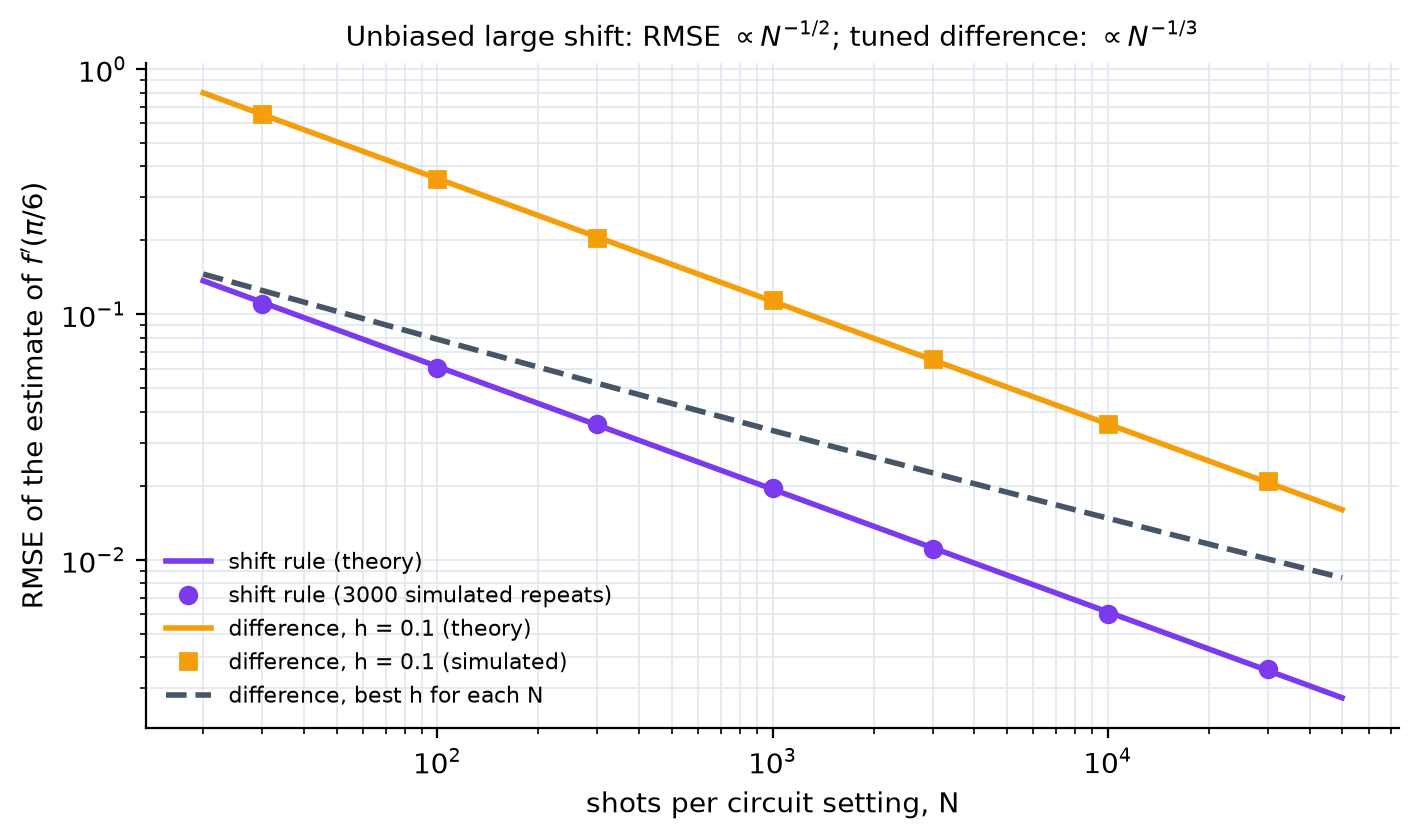

In [5]:
_show_mpl(_lessonfigs.rmse_vs_shots())

*RMSE against shots per setting on log-log axes, theory as lines and 3000 simulated repeats as markers. A fixed step $h = 0.1$ has the right slope but a large constant; even the best step for each $N$ only reaches slope $-1/3$, while the shift rule has slope $-1/2$.*

Simulate shot noise and compare measured spread with the formulas, including the near-optimal step $h = 0.46$. The last lines count the circuit settings and shots of one full-batch gradient for the lab model.


In [6]:
# Shot noise: N shots per circuit setting, outcome +1 / -1, estimate f_hat = mean.  f(t) = cos t at t = pi/6.
rng = np.random.default_rng(2026)
th, N, reps = math.pi / 6, 1000, 4000
true = -math.sin(th)

def f_hat(x):
    return 2 * rng.binomial(N, (1 + math.cos(x)) / 2, size=reps) / N - 1

ps = 0.5 * (f_hat(th + math.pi / 2) - f_hat(th - math.pi / 2))
var_ps = ((1 - math.cos(th + math.pi / 2) ** 2) + (1 - math.cos(th - math.pi / 2) ** 2)) / (4 * N)
print(f"shift rule      : mean {ps.mean():+.4f}  sd {ps.std():.4f}  theory sd {math.sqrt(var_ps):.4f}  bound {math.sqrt(1 / (2 * N)):.4f}")
for h in (0.1, 0.46):
    fd = (f_hat(th + h) - f_hat(th - h)) / (2 * h)
    bias = true * (math.sin(h) / h - 1)
    var = ((1 - math.cos(th + h) ** 2) + (1 - math.cos(th - h) ** 2)) / (4 * h * h * N)
    print(f"difference h={h:<4}: mean {fd.mean():+.4f}  sd {fd.std():.4f}  theory sd {math.sqrt(var):.4f}  "
          f"bias {bias:+.5f}  RMSE {math.sqrt(np.mean((fd - true) ** 2)):.4f}")
    assert abs(fd.std() - math.sqrt(var)) / math.sqrt(var) < 0.06
assert abs(ps.std() - math.sqrt(var_ps)) / math.sqrt(var_ps) < 0.06 and abs(ps.mean() - true) < 4 * math.sqrt(var_ps / reps)

# Cost of one full-batch gradient of a loss over m inputs, p parameters each used once
p, m = 2, 15
print("circuit settings per gradient:", 2 * p * m, " shots per gradient at N = 1000:", 2 * p * m * N)

shift rule      : mean -0.4998  sd 0.0196  theory sd 0.0194  bound 0.0224
difference h=0.1 : mean -0.4991  sd 0.1117  theory sd 0.1129  bias +0.00083  RMSE 0.1117
difference h=0.46: mean -0.4825  sd 0.0285  theory sd 0.0287  bias +0.01745  RMSE 0.0335
circuit settings per gradient: 60  shots per gradient at N = 1000: 60000


:::{note} Nonlinear losses and independent batches
For a loss $\ell(f)$ the chain rule gives $\partial_k \ell = \ell'(f)\,\partial_k f$. With squared loss, $\partial_k (f - y)^2 = 2(f - y)\partial_k f$. The plug-in estimate $2(\hat f - y)\hat g_k$ is unbiased when $\hat f$ and $\hat g_k$ come from independent shots, because then the expectation of the product is the product of expectations. If the two estimates were correlated (for example, built from shared shots), the product would be off by their covariance, a bias of order $1/N$.
:::

## Training: the landscape and what one step costs

Lab 8 fits the re-uploading model to 15 noiseless targets generated by $\boldsymbol\theta^\ast = (1.1, 0.7)$ with the mean squared error $L(\boldsymbol\theta) = \tfrac{1}{15}\sum_j (f_{\boldsymbol\theta}(x_j) - y_j)^2$. Each step needs $\partial_k f_{\boldsymbol\theta}(x_j)$ for 2 parameters and 15 inputs, two shifted settings each: 60 circuit settings per step, or $60N$ shots.

:::{figure} ../../_static/animations/l7_02_loss_landscape.mp4
:alt: A colored three-dimensional loss surface over two angles with a red ball rolling down a gradient-descent path to a minimum.
:width: 100%

Gradient descent on $L(\theta_0, \theta_1)$ with exact parameter-shift gradients, from $(0.3, -2.2)$ with step size 0.4. It reaches a minimum that is a symmetric copy of $\boldsymbol\theta^\ast$, not $\boldsymbol\theta^\ast$ itself.
:::

:::{dropdown} What the animation shows
The loss surface of the lab model is drawn over $\theta_0, \theta_1 \in [-\pi, \pi]$, colored from blue (low) to red (high); its maximum is about 2.09. The loss formula and its gradient are shown, with the note that each step uses 60 circuit settings. A red ball starts at $(0.3, -2.2)$, where the loss is 1.278, and follows 80 gradient-descent steps; its trail descends into a valley and ends near $(-0.70, -1.10)$ with loss below $10^{-9}$. A readout notes that this point is a symmetric copy of $\boldsymbol\theta^\ast = (1.1, 0.7)$, because the model is unchanged when both angles are negated and swapped. The camera then rotates slowly.
:::


In [7]:
_show(_lessonfigs.loss_surface())

**Explore.** The same landscape in 3-D; drag to rotate, and move the slider to reveal the descent path step by step.

:::{dropdown} What the figure shows
A translucent surface shows the loss over $(\theta_0, \theta_1)$ with several equal minima. A red path starts at $(0.3, -2.2)$; the slider reveals it after 0, 2, 5, 9, 14, 19, 29, 44, 59 and 80 steps, ending at a global minimum near $(-0.70, -1.10)$.
:::

:::{prf:remark} What the landscape does not tell you
Two parameters and noiseless targets make this landscape benign. It says nothing about how gradients behave as qubits and depth grow; that is the barren-plateau question of [L7-04](#lesson-l7-04), where gradient variance can shrink exponentially for specified circuit ensembles [@plateaus], and noise can cause the same effect [@noise]. An exact gradient rule does not help when the true gradient is smaller than the shot noise $1/\sqrt{2N}$.
:::

## Worked example

:::{admonition} A full gradient step for a two-parameter model, with its cost
:class: tip

For the lab model $f_{\boldsymbol\theta}(x) = \cos\theta_0\cos\theta_1 - \sin\theta_0\sin\theta_1\cos x$ at $\boldsymbol\theta = (\pi/2, \pi/2)$ and the single training pair $(x, y) = (0, 0.5)$, compute the squared-loss gradient with the shift rule, take one step with learning rate $0.5$, and count the circuit settings used.

1. Value: $f = \cos\tfrac{\pi}{2}\cos\tfrac{\pi}{2} - \sin\tfrac{\pi}{2}\sin\tfrac{\pi}{2}\cos 0 = 0 - 1 = -1$.
2. Shift in $\theta_0$: $f(\pi, \pi/2) = \cos\pi\cos\tfrac{\pi}{2} - \sin\pi\sin\tfrac{\pi}{2} = 0$ and $f(0, \pi/2) = \cos 0\cos\tfrac{\pi}{2} - 0 = 0$, so $\partial_0 f = \tfrac{1}{2}(0 - 0) = 0$. By the symmetry of the model in its two angles, $\partial_1 f = 0$ too. Check against the closed form $\partial_0 f = -\sin\theta_0\cos\theta_1 - \cos\theta_0\sin\theta_1\cos x = 0$.
3. Chain rule: $\partial_k (f - y)^2 = 2(f - y)\partial_k f = 2(-1.5)(0) = 0$. At $x = 0$ the model is $\cos(\theta_0 + \theta_1)$, which reaches its minimum $-1$ here, so $(f - y)^2$ is as large as it can be: the point is a maximum of the loss. The step leaves $\boldsymbol\theta$ unchanged even though the loss is $2.25$.
4. Cost: one value circuit plus $2 \times 2 = 4$ shifted circuits, 5 settings. With noisy estimates, the gradient would be pure noise of size about $1/\sqrt{2N}$ per component, which would push the parameters off the stationary point at random.

**Result.** The gradient is exactly zero at $(\pi/2, \pi/2)$ although the loss is $2.25$: an exact rule finds stationary points faithfully, including bad ones. Five circuit settings were needed; with $N$ shots each, a full step costs $5N$ shots for one data point.
:::

## Exercises

**1. (Core)** For $R_Y(\theta)|0\rangle$ measured in $Z$, compute $f'(\pi/3)$ with the shift rule. For the squared loss $(f - y)^2$, write its derivative in terms of $f'$.

:::{dropdown} Solution
$f(\pi/3 + \pi/2) = \cos(5\pi/6) = -\sqrt3/2$ and $f(\pi/3 - \pi/2) = \cos(-\pi/6) = \sqrt3/2$, so $f'(\pi/3) = \tfrac{1}{2}(-\sqrt3/2 - \sqrt3/2) = -\sqrt3/2$, equal to $-\sin(\pi/3)$. The loss derivative is $2(f - y)f'(\theta)$; the rule supplies $f'$ and the chain rule is classical.
:::

**2. (Core)** A gate is written $e^{-i\theta X}$ (no factor $\tfrac{1}{2}$). Derive its two-term shift rule from [](#eq-l7-02-shift).

:::{dropdown} Solution
$e^{-i\theta X} = e^{-i(2\theta)X/2}$, so $f(\theta) = g(2\theta)$ where $g$ obeys the standard rule. Then $f'(\theta) = 2g'(2\theta) = 2\cdot\tfrac{1}{2}[g(2\theta + \tfrac{\pi}{2}) - g(2\theta - \tfrac{\pi}{2})] = f(\theta + \tfrac{\pi}{4}) - f(\theta - \tfrac{\pi}{4})$. This matches $r[f(\theta + \tfrac{\pi}{4r}) - f(\theta - \tfrac{\pi}{4r})]$ with $r = 1$.
:::

**3. (Stretch)** A parameter $\theta$ appears in two gates, $R_Y(\theta)R_Y(\theta)|0\rangle$, measured in $Z$. (a) Show that shifting $\theta$ by $\pm\pi/2$ in both gates at once returns 0 for every $\theta$. (b) Give the correct estimator and check it at $\theta = \pi/8$.

:::{dropdown} Solution
(a) $f(\theta) = \cos 2\theta$, so the naive estimate is $\tfrac{1}{2}[\cos(2\theta + \pi) - \cos(2\theta - \pi)] = \tfrac{1}{2}[-\cos 2\theta + \cos 2\theta] = 0$. (b) Name the occurrences $\theta_1, \theta_2$; then $f' = \partial_1 f + \partial_2 f$ at $\theta_1 = \theta_2 = \theta$. Each partial derivative is a two-term rule in its own gate: $\partial_1 f = \tfrac{1}{2}[\cos(2\theta + \tfrac{\pi}{2}) - \cos(2\theta - \tfrac{\pi}{2})] = -\sin 2\theta$, and the same for $\partial_2$. The sum is $-2\sin 2\theta$, which at $\pi/8$ is $-\sqrt2 \approx -1.414$, matching the code. It costs 4 settings instead of 2.
:::

**4. (Stretch)** Using [](#eq-l7-02-fdopt), show that the optimally tuned central difference needs about $N \propto \epsilon^{-3}$ shots per setting for RMSE $\epsilon$, while the shift rule needs $N \le 1/(2\epsilon^2)$. How many shots per setting does each need for $\epsilon = 0.01$ at $\theta = \pi/6$, using $V \approx \sin^2\theta$ and $|f'| = \sin\theta$?

:::{dropdown} Solution
With $h^\ast$ substituted, $\operatorname{MSE} \approx f'^2 (h^\ast)^4/12$ and $(h^\ast)^6 = 9V/(f'^2 N)$, so $\operatorname{MSE} = \tfrac{f'^2}{12}(9V/(f'^2N))^{2/3} \propto N^{-2/3}$, and $\operatorname{RMSE} = \epsilon$ needs $N \propto \epsilon^{-3}$. Here $V/f'^2 = 1$, so $\operatorname{MSE} = \tfrac{0.25}{12}(9/N)^{2/3}$. Setting it to $10^{-4}$: $(9/N)^{2/3} = 0.0048$, $9/N = 0.0048^{1.5} = 3.33\times 10^{-4}$, $N \approx 2.7\times 10^4$. The shift rule has exact variance $0.375/N$ here, so $N = 0.375/10^{-4} = 3750$ (the worst-case bound $1/(2\epsilon^2)$ gives 5000). The tuned difference needs about 7 times more shots, and the factor grows like $\epsilon^{-1}$.
:::

**5. (Challenge)** Prove that among unbiased estimators of the form $\hat g = \alpha[\hat f(\theta + s) - \hat f(\theta - s)]$ that are exact for every function $a + b\cos\theta + c\sin\theta$, the worst-case variance bound $\alpha^2 \cdot 2/N$ is minimized by $s = \pi/2$. Then explain why this optimality statement says nothing about estimators that use three or more settings.

:::{dropdown} Solution
Exactness for all $(b, c)$ forces $\alpha = 1/(2\sin s)$ by the theorem (take $b = 0, c = 1, \theta = 0$: $\alpha\cdot 2\sin s = 1$). The worst case of $(1 - f_+^2) + (1 - f_-^2)$ is 2, so the bound is $2\alpha^2/N = 1/(2N\sin^2 s)$, minimized when $\sin^2 s = 1$, that is $s = \pi/2$ (mod $\pi$). The argument restricts to two symmetric settings with equal shots; estimators with more settings or unequal shot allocation form a larger class, and comparing them requires a separate optimization (and a fixed total shot budget), so no conclusion about them follows.
:::

**6. (Challenge)** Show that for $U(\theta) = e^{-i\theta G}$ with $G$ having eigenvalues $\{-1, 0, 1\}$, the function $f$ can contain frequencies 0, 1 and 2, and give an explicit $3\times 3$ example where $\tfrac{1}{2}[f(\theta + \tfrac{\pi}{2}) - f(\theta - \tfrac{\pi}{2})] \ne f'(\theta)$ for the matching two-term formula.

:::{dropdown} Solution
By the proposition, frequencies are differences of eigenvalues: $0, \pm1, \pm2$. Example: $G = \operatorname{diag}(1, 0, -1)$, $|\psi\rangle = (1, 0, 1)/\sqrt2$, $A = |0\rangle\langle 2| + |2\rangle\langle 0|$ (basis $0, 1, 2$). Then $U|\psi\rangle = (e^{-i\theta}, 0, e^{i\theta})/\sqrt2$ and $f(\theta) = \tfrac{1}{2}(e^{i\theta}e^{i\theta} + e^{-i\theta}e^{-i\theta}) = \cos 2\theta$. The true derivative is $-2\sin 2\theta$. A two-term rule built for frequency 1 would use $s$ with $\sin s$ in the denominator; with $s = \pi/2$ and factor $\tfrac{1}{2}$ it gives $\tfrac{1}{2}[\cos(2\theta + \pi) - \cos(2\theta - \pi)] = 0 \ne -2\sin 2\theta$ for $\theta = \pi/8$, say. (A rule matched to frequency 2, $f'(\theta) = f(\theta + \tfrac{\pi}{4}) - f(\theta - \tfrac{\pi}{4})$, works here only because frequency 1 happens to be absent; in general both frequencies appear and two terms do not suffice; the general rule for $R = 2$ frequencies uses four evaluations [@wierichs2022].)
:::

## Check your understanding

**1. For a gate $e^{-i\theta P/2}$ with $P^2 = I$, what is $\tfrac{1}{2}[f(\theta + \tfrac{\pi}{2}) - f(\theta - \tfrac{\pi}{2})]$?**

- **A.** The slope of the chord between the two shifted points
- **B.** An estimate of $f'(\theta)$ with zero variance on hardware
- **C.** An approximation to $f'(\theta)$ with error of order $(\pi/2)^2$
- **D.** Exactly $f'(\theta)$ for the ideal expectation

:::{dropdown} Show the answer
**D. Exactly $f'(\theta)$ for the ideal expectation**

The expectation is $a + b\cos\theta + c\sin\theta$, and the identity is exact for every such function. The chord slope divides by $\pi$, not 2, and is $\tfrac{2}{\pi}f'$. With finite shots the estimate is unbiased but still noisy.
:::

**2. At equal shots per setting, why is a central difference with a small step worse than the shift rule on hardware?**

- **A.** It cannot be applied to Pauli rotations
- **B.** It needs four circuit settings per parameter
- **C.** It is biased for every step, however small, by a fixed amount
- **D.** Its variance grows like $1/h^2$ as the step shrinks

:::{dropdown} Show the answer
**D. Its variance grows like $1/h^2$ as the step shrinks**

The difference of two noisy estimates is divided by $2h$, so its variance is up to $1/(2Nh^2)$. Small $h$ reduces bias like $h^2$ but inflates noise; the tuned compromise converges as $N^{-1/3}$ in RMSE.
:::

**3. A parameter appears in three Pauli rotations of a circuit. How many circuit settings does an exact shift-rule derivative with respect to it need?**

- **A.** 2: shift the shared value once in all gates
- **B.** 6: one shifted pair per occurrence, summed
- **C.** 1: the derivative can be read off one circuit
- **D.** 3: one per occurrence

:::{dropdown} Show the answer
**B. 6: one shifted pair per occurrence, summed**

By the product rule the derivative is the sum of the partial derivatives for each occurrence, each a two-term rule. Shifting all occurrences together gives a different, generally wrong, combination.
:::

**4. For $f(\theta) = \cos\theta$, what is the exact value of the central difference $[f(\theta + h) - f(\theta - h)]/(2h)$?** *(Review of [L3-06](#lesson-l3-06))*

- **A.** $-\sin\theta$
- **B.** $-\sin\theta + h^2$
- **C.** $-\cos\theta\cdot h$
- **D.** $-\sin\theta\cdot\sin h/h$

:::{dropdown} Show the answer
**D. $-\sin\theta\cdot\sin h/h$**

$\cos(\theta + h) - \cos(\theta - h) = -2\sin\theta\sin h$. Dividing by $2h$ gives $-\sin\theta\,\sin h/h$, which tends to the derivative $-\sin\theta$ as $h \to 0$, with relative error about $h^2/6$.
:::

## Common misconceptions

- **"The parameter-shift rule is a finite difference with a big step."** A finite difference divides by the step and is exact only in the limit. The shift rule divides by $2\sin s$ and is exact at every $s$ because the function is a single sinusoid; at $s = \pi/2$ the chord slope is $\tfrac{2}{\pi}f'$, not $f'$.
- **"An exact gradient formula means exact gradients on hardware."** The formula is exact for expectations. Each expectation is estimated from $N$ shots, so the gradient estimate has standard deviation up to $1/\sqrt{2N}$, and device errors can bias the expectations themselves.
- **"Any parametrized gate can be differentiated with two shifted circuits."** Only gates whose generator has two eigenvalues (frequency set $\{0, \pm 1\}$ after rescaling). Shared parameters need one pair per occurrence, and generators with more eigenvalues give more frequencies and need more evaluations.
- **"Finding a point where the estimated gradient is zero means the model is trained."** Exact gradients vanish at maxima and saddles too (the worked example), and noisy estimates near zero can hide a nonzero gradient. Check the loss, and check scaling before calling a landscape flat.

:::{caution} Scope and limits
Every number here comes from noiseless classical simulation with ideal sampling; real devices add gate errors, readout bias and drift, which can bias the expectations that the rule differentiates. The two-term rule assumes a single occurrence of the parameter in a gate $e^{-i\theta P/2}$ with $P^2 = I$ (or its rescaled form). The finite-difference comparison uses the central difference and independent shot batches; the $N^{-1/3}$ rate is the leading-order behavior from a Taylor model of the bias. Nothing here addresses trainability at scale or any quantum advantage.
:::

:::{seealso} Where this leads
The shot-noise bound $1/(2N)$ on the shift-rule variance is the quantity that [L7-04](#lesson-l7-04) compares with gradient variance across random circuits, and the count of $2p$ settings per input enters the resource accounting of [L7-06](#lesson-l7-06). The frequency picture returns in [L7-03](#lesson-l7-03): the same feature-map circuits that define variational models define quantum kernels.
:::

:::{dropdown} For instructors

**Why this lesson.** Parameter-shift gradients are the standard way to train variational circuits on hardware [@vqa], and they are often taught as a recipe. Deriving them from the spectral structure of the generator makes the conditions visible, and the bias and variance analysis turns a formula into a resource statement that research students need when they read or write training claims [@mitarai; @schuld].

**Teaching notes.**

- Ask students to predict the slope of the chord between $\theta \pm \pi/2$ before showing the first animation; many expect it to equal the derivative. The factor $\tfrac{2}{\pi}$ is a memorable correction.
- Run the shared-parameter code cell live: the naive shift returning exactly zero is a vivid failure that motivates checking conditions.
- Have students reproduce $h^\ast \approx 0.46$ at $N = 1000$ from [](#eq-l7-02-fdopt) and then confirm it with the interactive figure.
- Connect the remark on automatic differentiation to cost: a simulator pays $2^n$ memory, hardware pays $2p$ settings per input.

**Assessment.** The stretch exercise on shared parameters and the challenge on optimal shifts test whether students can derive rather than recall. A good written answer to the second check question uses the $1/(2Nh^2)$ bound explicitly.

**Going further.** Derive the stochastic version of the gradient step: with independent shot batches, show that $2(\hat f - y)\hat g$ is unbiased for the loss gradient and compute its variance. Then read the conditions in Schuld and coauthors for gates whose generators are not involutions [@schuld] and the general shift rules of Wierichs and coauthors for generators with several frequencies [@wierichs2022], and the survey of variational algorithms for how these gradients enter practical optimizers [@vqa].

:::

## References

This lesson draws on [@mitarai; @schuld; @vqa; @pennylane; @encoding; @wierichs2022].

**Further reading.**

- [@mml]: Chapter 5 covers gradients, the chain rule and automatic differentiation for machine learning.
- [@plateaus]: What happens to these gradients as random circuits grow; the topic of L7-04.
- [@openstax_derivative]: The limit definition of the derivative that finite differences approximate.

**Next:** [L7-03 · Quantum kernels and data access](#lesson-l7-03)
